# Guided Project 01 · 从零完成 GridWorld Q-learning

[返回项目目录](README.md) · [对应 Chapter05](../02_chapters/Chapter05.ipynb) · [实验模板](Experiment_Template.ipynb)

这是第一个必须真正完成的 RL 项目。我们会经历：定义问题 → 验证环境 → 随机基线 → Q-learning → 独立评估 → 曲线诊断 → 故障注入。


## 1. 先把问题说清楚

5×5 网格，起点左上、终点右下，中间有障碍。动作是上/下/左/右；每步奖励 -0.02，撞障碍额外 -0.08，到达终点奖励 +1。状态是格子编号，因此 Q 表 shape 为 `(25,4)`。

$$Q(s,a)\leftarrow Q(s,a)+\alpha[r+\gamma(1-d)\max_{a'}Q(s',a')-Q(s,a)]$$

代码中的 `done` 必须和公式里的 $(1-d)$ 对应。


In [1]:
import numpy as np
import matplotlib.pyplot as plt

class GridWorld:
    def __init__(self):
        self.size = 5
        self.start, self.goal = (0, 0), (4, 4)
        self.obstacles = {(1, 1), (2, 1), (3, 3)}
        self.moves = [(-1, 0), (1, 0), (0, -1), (0, 1)]
        self.reset()

    def encode(self, pos):
        return pos[0] * self.size + pos[1]

    def reset(self):
        self.pos = self.start
        return self.encode(self.pos)

    def step(self, action):
        row, col = self.pos; dr, dc = self.moves[action]
        candidate = (int(np.clip(row+dr, 0, 4)), int(np.clip(col+dc, 0, 4)))
        hit_obstacle = candidate in self.obstacles
        if not hit_obstacle:
            self.pos = candidate
        done = self.pos == self.goal
        reward = 1.0 if done else (-0.10 if hit_obstacle else -0.02)
        return self.encode(self.pos), reward, done

env = GridWorld()
assert env.reset() == 0 and env.encode(env.goal) == 24
print("states/actions:", 25, 4, "obstacles:", env.obstacles)


states/actions: 25 4 obstacles: {(1, 1), (3, 3), (2, 1)}


## 2. 环境测试早于训练

在学习算法之前，用固定动作检查边界、障碍和终点。如果环境错了，agent 可能非常成功地优化一个错误任务。


In [2]:
env.reset()
state, reward, done = env.step(0)  # 在顶边向上
assert state == 0 and reward == -0.02 and not done
env.reset(); env.step(3)           # 到 (0,1)
state, reward, done = env.step(1)  # 向下撞 (1,1)
assert state == 1 and reward == -0.10 and not done
print("boundary and obstacle tests passed")


boundary and obstacle tests passed


## 3. 随机基线

baseline 回答“学习算法至少要超过谁”。这里记录 success rate、return 和 episode length，而不是只看是否偶尔到达终点。


In [3]:
def evaluate_policy(policy, episodes=200, seed=0):
    rng = np.random.default_rng(seed)
    returns, lengths, successes = [], [], []
    for _ in range(episodes):
        state, total = env.reset(), 0.0
        for step in range(100):
            action = policy(state, rng)
            state, reward, done = env.step(action)
            total += reward
            if done: break
        returns.append(total); lengths.append(step+1); successes.append(done)
    return np.asarray(returns), np.asarray(lengths), np.asarray(successes)

random_result = evaluate_policy(lambda state, rng: int(rng.integers(4)))
print("random success / return / length:",
      random_result[2].mean(), random_result[0].mean(), random_result[1].mean())


random success / return / length: 0.505 -1.7172000000000014 76.535


## 4. 训练 Q-learning

epsilon 负责收集不同动作的数据；学习率控制一次 TD error 改多少；折扣因子控制未来终点奖励能传多远。先固定三个参数建立基线，再逐个调整。


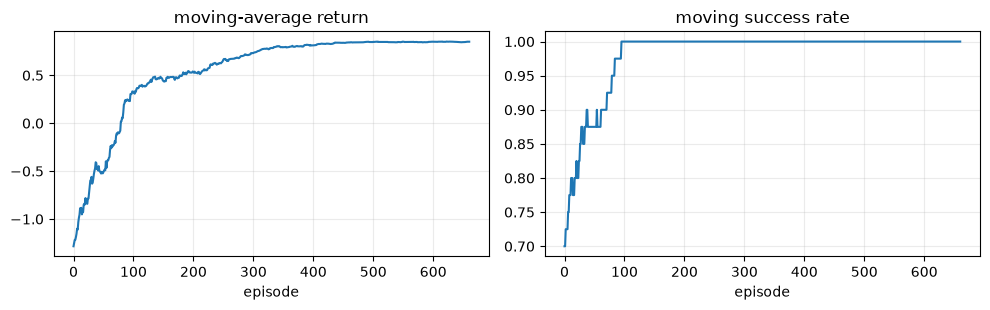

last-100 success/return/length: 1.0 0.8495999999999999 8.32


In [4]:
def train_q_learning(seed=0, episodes=700, alpha=.2, gamma=.97, explore=True, initial_action0_bias=False):
    rng = np.random.default_rng(seed)
    q = np.zeros((25, 4), dtype=np.float64)
    if initial_action0_bias:
        q[:, 0] = 1.0
    returns, successes, lengths = [], [], []
    for episode in range(episodes):
        state, total, done = env.reset(), 0.0, False
        epsilon = max(.05, 1.0 - episode/500) if explore else 0.0
        for step in range(100):
            action = int(rng.integers(4)) if rng.random() < epsilon else int(q[state].argmax())
            next_state, reward, done = env.step(action)
            target = reward if done else reward + gamma*q[next_state].max()
            q[state, action] += alpha*(target - q[state, action])
            state, total = next_state, total + reward
            if done: break
        returns.append(total); successes.append(done); lengths.append(step+1)
    return q, np.asarray(returns), np.asarray(successes), np.asarray(lengths)

q, returns, successes, lengths = train_q_learning(seed=10)
window = 40
smooth_return = np.convolve(returns, np.ones(window)/window, mode="valid")
smooth_success = np.convolve(successes, np.ones(window)/window, mode="valid")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(smooth_return); axes[0].set_title("moving-average return")
axes[1].plot(smooth_success); axes[1].set_title("moving success rate")
for ax in axes: ax.set_xlabel("episode"); ax.grid(alpha=.25)
plt.tight_layout(); plt.show(); plt.close()
print("last-100 success/return/length:", successes[-100:].mean(), returns[-100:].mean(), lengths[-100:].mean())


## 5. 独立评估与路径检查

评估时关闭 epsilon，使用新的 episode，不再更新 Q。成功率高仍不够：还要查看路径是否循环、是否明显长于最短路。


In [5]:
greedy = lambda state, rng: int(q[state].argmax())
eval_returns, eval_lengths, eval_successes = evaluate_policy(greedy, episodes=100, seed=999)

state, path = env.reset(), [env.pos]
for _ in range(30):
    state, _, done = env.step(int(q[state].argmax()))
    path.append(env.pos)
    if done: break
print("evaluation success / mean length:", eval_successes.mean(), eval_lengths.mean())
print("greedy path:", path)
assert eval_successes.mean() > .95 and path[-1] == env.goal


evaluation success / mean length: 1.0 8.0
greedy path: [(0, 0), (1, 0), (2, 0), (3, 0), (3, 1), (3, 2), (4, 2), (4, 3), (4, 4)]


## 6. 故障注入：完全不探索

如果初始估计偏向动作 0，同时 epsilon 从一开始就是 0，agent 会在顶边反复向上，永远看不到终点奖励。这不是学习率问题，而是数据覆盖问题。


In [6]:
q_bad, bad_returns, bad_successes, _ = train_q_learning(
    seed=10, episodes=5, explore=False, initial_action0_bias=True
)
print("first-five no-exploration success:", bad_successes.mean())
assert bad_successes.sum() == 0


first-five no-exploration success: 0.0


## 7. 调参顺序与验收

1. 固定 seed，确保环境测试和随机基线可信。
2. 只调 epsilon schedule，先获得稳定成功轨迹。
3. 比较 learning rate 的稳定性，再调 gamma。
4. 用 5 个 seed 重复；报告均值和失败 seed。

**项目验收：**评估成功率 >95%；能从空白写出 TD target；能解释无探索为何失败；能添加一个陷阱格并预测策略变化。

**下一步：**先完成对应的 [Chapter05](../02_chapters/Chapter05.ipynb)，再进入 [DQN CartPole](Guided_Project02_DQN_CartPole.ipynb)。
